# Tugas P2. Representasi Data & Pra-pemrosesan
MK. Pembelajaran Mesin | Muhammad Dwi Putra | NIM 10124049

Klasifikator (NIM ganjil): Naive Bayes Gaussian

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score

pd.set_option('display.max_columns', None)   # tampilkan semua kolom

## 1. Load dataset

In [5]:
df = pd.read_csv('/content/heart_disease.csv')   # ganti path jika tidak memakai Colab
target = 'Heart Disease Status'

## 2. Info dan tipe kolom

In [6]:
print("Ukuran data:", df.shape)
df.info()
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(exclude='number').columns

Ukuran data: (10000, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           9975 non-null   float64


## 3. Jenis data berdasarkan jenis pengukuran

In [7]:
jenis_ukur = {
    'Age': 'Rasio', 'Gender': 'Nominal', 'Blood Pressure': 'Rasio',
    'Cholesterol Level': 'Rasio', 'Exercise Habits': 'Ordinal',
    'Smoking': 'Nominal', 'Family Heart Disease': 'Nominal',
    'Diabetes': 'Nominal', 'BMI': 'Rasio', 'High Blood Pressure': 'Nominal',
    'Low HDL Cholesterol': 'Nominal', 'High LDL Cholesterol': 'Nominal',
    'Alcohol Consumption': 'Ordinal', 'Stress Level': 'Ordinal',
    'Sleep Hours': 'Rasio', 'Sugar Consumption': 'Ordinal',
    'Triglyceride Level': 'Rasio', 'Fasting Blood Sugar': 'Rasio',
    'CRP Level': 'Rasio', 'Homocysteine Level': 'Rasio', target: 'Nominal'}
print("\nJumlah kolom per jenis pengukuran:")
print(pd.Series(jenis_ukur).value_counts())


Jumlah kolom per jenis pengukuran:
Rasio      9
Nominal    8
Ordinal    4
Name: count, dtype: int64


## 4. Missing values (median untuk numerik, modus untuk kategorikal)

In [8]:
miss = df.isna().sum()
print("\nMissing values per kolom:\n", miss[miss > 0])
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
print("Sisa missing value:", df.isna().sum().sum())


Missing values per kolom:
 Age                       29
Gender                    19
Blood Pressure            19
Cholesterol Level         30
Exercise Habits           25
Smoking                   25
Family Heart Disease      21
Diabetes                  30
BMI                       22
High Blood Pressure       26
Low HDL Cholesterol       25
High LDL Cholesterol      26
Alcohol Consumption     2586
Stress Level              22
Sleep Hours               25
Sugar Consumption         30
Triglyceride Level        26
Fasting Blood Sugar       22
CRP Level                 26
Homocysteine Level        20
dtype: int64
Sisa missing value: 0


## 5. Duplikasi

In [9]:
print("\nJumlah duplikat:", df.duplicated().sum())
df = df.drop_duplicates()


Jumlah duplikat: 0


## 6. Cek kategori (ejaan dan kapitalisasi)

In [10]:
print("\nNilai unik kolom kategorikal:")
for col in cat_cols:
    print(col, sorted(df[col].unique()))


Nilai unik kolom kategorikal:
Gender ['Female', 'Male']
Exercise Habits ['High', 'Low', 'Medium']
Smoking ['No', 'Yes']
Family Heart Disease ['No', 'Yes']
Diabetes ['No', 'Yes']
High Blood Pressure ['No', 'Yes']
Low HDL Cholesterol ['No', 'Yes']
High LDL Cholesterol ['No', 'Yes']
Alcohol Consumption ['High', 'Low', 'Medium']
Stress Level ['High', 'Low', 'Medium']
Sugar Consumption ['High', 'Low', 'Medium']
Heart Disease Status ['No', 'Yes']


## 7. Outlier (IQR), dihitung pada skala asli

In [11]:
Q1, Q3 = df['Cholesterol Level'].quantile([0.25, 0.75])
IQR = Q3 - Q1
batas_bawah, batas_atas = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print("\nCholesterol Level: Q1 =", Q1, "Q3 =", Q3, "IQR =", IQR)
print("Batas IQR:", batas_bawah, "sampai", batas_atas)
mask = df['Cholesterol Level'].between(batas_bawah, batas_atas)
print("Jumlah outlier:", (~mask).sum())
df_clean = df[mask]

# pengecekan yang sama untuk semua kolom numerik
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"  {col}: {n} outlier")


Cholesterol Level: Q1 = 187.0 Q3 = 263.0 IQR = 76.0
Batas IQR: 73.0 sampai 377.0
Jumlah outlier: 0
  Age: 0 outlier
  Blood Pressure: 0 outlier
  Cholesterol Level: 0 outlier
  BMI: 0 outlier
  Sleep Hours: 0 outlier
  Triglyceride Level: 0 outlier
  Fasting Blood Sugar: 0 outlier
  CRP Level: 0 outlier
  Homocysteine Level: 0 outlier


## 8. Encoding kategori menjadi angka

In [12]:
ordinal_cols = ['Exercise Habits', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption']
urutan = {'Low': 0, 'Medium': 1, 'High': 2}              # ordinal: urutan dipertahankan
biner = {'No': 0, 'Yes': 1, 'Female': 0, 'Male': 1}      # nominal biner

df_processed = df_clean.copy()
for col in ordinal_cols:
    df_processed[col] = df_processed[col].map(urutan)
for col in cat_cols:
    if col not in ordinal_cols:
        df_processed[col] = df_processed[col].map(biner)   # termasuk kolom target
print("\nSisa kolom non-numerik:", list(df_processed.select_dtypes(exclude='number').columns))
print("Missing setelah encoding:", df_processed.isna().sum().sum())


Sisa kolom non-numerik: []
Missing setelah encoding: 0


## 9. Ketidakseimbangan kelas

In [13]:
print("\nDistribusi target (0 = No, 1 = Yes):")
print(df_processed[target].value_counts())
print((df_processed[target].value_counts(normalize=True) * 100).round(2))


Distribusi target (0 = No, 1 = Yes):
Heart Disease Status
0    8000
1    2000
Name: count, dtype: int64
Heart Disease Status
0    80.0
1    20.0
Name: proportion, dtype: float64


## 10. Indikasi kebocoran data (korelasi fitur dengan target)

In [14]:
korelasi = df_processed.drop(columns=target).corrwith(df_processed[target])
print("\nKorelasi fitur dengan target:")
print(korelasi.round(4))


Korelasi fitur dengan target:
Age                    -0.0092
Gender                 -0.0172
Blood Pressure         -0.0139
Cholesterol Level       0.0027
Exercise Habits         0.0018
Smoking                 0.0027
Family Heart Disease   -0.0075
Diabetes               -0.0027
BMI                     0.0197
High Blood Pressure     0.0022
Low HDL Cholesterol    -0.0060
High LDL Cholesterol    0.0082
Alcohol Consumption     0.0048
Stress Level            0.0113
Sleep Hours            -0.0038
Sugar Consumption       0.0073
Triglyceride Level      0.0029
Fasting Blood Sugar    -0.0022
CRP Level              -0.0060
Homocysteine Level      0.0083
dtype: float64


## 11. Kesesuaian dengan asumsi Gaussian (bentuk distribusi fitur numerik)

In [15]:
print("\nSkewness dan kurtosis fitur numerik (distribusi normal: 0 dan 0):")
print(pd.DataFrame({'skewness': df_processed[num_cols].skew(),
                    'kurtosis': df_processed[num_cols].kurt()}).round(2))


Skewness dan kurtosis fitur numerik (distribusi normal: 0 dan 0):
                     skewness  kurtosis
Age                     -0.01     -1.20
Blood Pressure           0.01     -1.21
Cholesterol Level       -0.01     -1.20
BMI                     -0.02     -1.18
Sleep Hours              0.00     -1.22
Triglyceride Level       0.01     -1.19
Fasting Blood Sugar     -0.01     -1.23
CRP Level               -0.00     -1.20
Homocysteine Level       0.01     -1.18


## 12. Uji: apakah standarisasi berpengaruh pada Gaussian Naive Bayes?

In [16]:
X = df_processed.drop(columns=target)
y = df_processed[target]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
sc = StandardScaler().fit(Xtr[num_cols])
Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
Xtr_s[num_cols] = sc.transform(Xtr[num_cols])
Xte_s[num_cols] = sc.transform(Xte[num_cols])
pred_asli = GaussianNB().fit(Xtr, ytr).predict(Xte)
pred_std = GaussianNB().fit(Xtr_s, ytr).predict(Xte_s)
print("\nProporsi prediksi sama (tanpa vs dengan standarisasi):", (pred_asli == pred_std).mean())
print("Akurasi:", round(accuracy_score(yte, pred_asli), 4),
      "| F1 kelas Yes:", round(f1_score(yte, pred_asli, zero_division=0), 4),
      "| Jumlah prediksi Yes:", pred_asli.sum(), "dari", len(pred_asli))


Proporsi prediksi sama (tanpa vs dengan standarisasi): 1.0
Akurasi: 0.8 | F1 kelas Yes: 0.0 | Jumlah prediksi Yes: 0 dari 2000


## 13. Lima data teratas dan lima data terbawah (data hasil pemrosesan)


=== 5 DATA TERATAS ===


,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,Low HDL Cholesterol,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,1,153.0,155.0,2,1,1,0,24.991591,1,1,0,2,1,7.633228,1,342.0,120.0,12.969246,12.387250,0
1,69.0,0,146.0,286.0,2,0,1,1,25.221799,0,1,0,1,2,8.744034,1,133.0,157.0,9.355389,19.298875,0
2,46.0,1,126.0,216.0,0,0,0,0,29.855447,0,1,1,0,0,4.440440,0,393.0,92.0,12.709873,11.230926,0
3,32.0,0,122.0,293.0,2,1,1,0,24.130477,1,0,1,0,2,5.249405,2,293.0,94.0,12.509046,5.961958,0
4,60.0,1,166.0,242.0,0,1,1,1,20.486289,1,0,0,0,2,7.030971,2,263.0,154.0,10.381259,8.153887,0



=== 5 DATA TERBAWAH ===


,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,Low HDL Cholesterol,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
9995,25.0,0,136.0,243.0,1,1,0,0,18.788791,1,0,1,1,2,6.834954,1,343.0,133.0,3.588814,19.132004,1
9996,38.0,1,172.0,154.0,1,0,0,0,31.856801,1,0,1,1,2,8.247784,0,377.0,83.0,2.658267,9.715709,1
9997,73.0,1,152.0,201.0,2,1,0,1,26.899911,0,1,1,1,0,4.436762,0,248.0,88.0,4.408867,9.492429,1
9998,23.0,1,142.0,299.0,0,1,0,1,34.964026,1,0,1,1,2,8.526329,1,113.0,153.0,7.215634,11.873486,1
9999,38.0,0,128.0,193.0,1,1,1,1,25.111295,0,1,1,2,1,5.659394,2,121.0,149.0,14.387810,6.208531,1


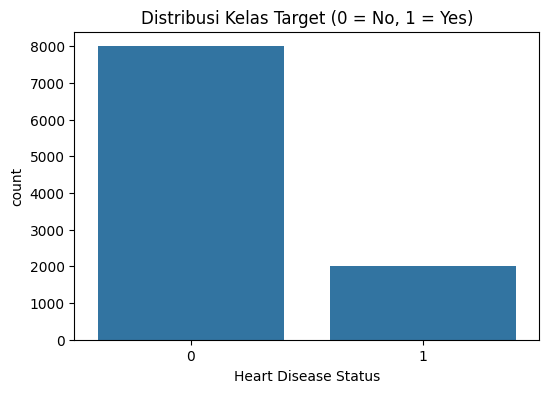

In [17]:
print("\n=== 5 DATA TERATAS ===")
display(df_processed.head(5))
print("\n=== 5 DATA TERBAWAH ===")
display(df_processed.tail(5))

plt.figure(figsize=(6, 4))
sns.countplot(data=df_processed, x=target)
plt.title('Distribusi Kelas Target (0 = No, 1 = Yes)')
plt.show()